# K-means 聚类 

在本练习中，你将实现 K-means 算法，并将其用于图像压缩。 

* 你将从一个示例数据集开始，帮助你直观理解 K-means 算法的工作原理。 
* 之后，你将用 K-means 算法进行图像压缩：把图像中出现的颜色数量减少到只有该图像中最常见的那些颜色。




# 大纲
- [ 1 - 实现 K-means](#1)
  - [ 1.1 寻找最近的质心](#1.1)
    - [ 练习 1](#ex01)
  - [ 1.2 计算质心均值](#1.2)
    - [ 练习 2](#ex02)
- [ 2 - 在示例数据集上运行 K-means ](#2)
- [ 3 - 随机初始化](#3)
- [ 4 - 用 K-means 压缩图像](#4)
  - [ 4.1 数据集](#4.1)
  - [ 4.2 在图像像素上运行 K-Means](#4.2)
  - [ 4.3 压缩图像](#4.3)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *

%matplotlib inline

<a name="1"></a>
## 1 - 实现 K-means

K-means 算法是一种自动把相似数据点聚到一起的方法。 

* 具体来说，给定训练集 $\{x^{(1)}, ..., x^{(m)}\}$，你想把数据分成若干内聚的“簇”。 


* K-means 是一个迭代过程：
     * 先猜测初始质心，然后 
     * 通过以下方式改进这个猜测： 
         * 反复把样本分配给离它最近的质心，然后 
         * 根据分配结果重新计算质心。
         

* 用伪代码表示，K-means 算法如下：

    ``` python
    # 初始化质心
    # K 是簇的数量
    centroids = kMeans_init_centroids(X, K)
    
    for iter in range(iterations):
        # 簇分配步骤： 
        # 把每个数据点分配给最近的质心。 
        # idx[i] 对应分配给样本 i 的质心索引
        idx = find_closest_centroids(X, centroids)

        # 移动质心步骤： 
        # 根据质心分配结果计算均值
        centroids = compute_means(X, idx, K)
    ```


* 算法的内层循环反复执行两个步骤： 
    * (i) 把每个训练样本 $x^{(i)}$ 分配给离它最近的质心，以及
    * (ii) 用分配给每个质心的点重新计算该质心的均值。 
    
    
* $K$-means 算法总会收敛到某一组最终的质心均值。 

* 但是，收敛得到的解并不总是理想的，它取决于质心的初始设置。
    * 因此，实践中通常用不同的随机初始化运行 K-means 算法若干次。 
    * 在这些来自不同随机初始化的解之间进行选择的一种方法，是选出代价函数值（失真度）最低的那个。

在接下来的几节中，你将分别实现 K-means 算法的两个阶段。 
* 你将先完成 `find_closest_centroid`，然后完成 `compute_centroids`。

<a name="1.1"></a>
### 1.1 寻找最近的质心

在 K-means 算法的“簇分配”阶段，算法根据质心的当前位置，把每个训练样本 $x^{(i)}$ 分配给离它最近的质心。 

<a name="ex01"></a>
### 练习 1

你的任务是补全 `find_closest_centroids` 中的代码。 
* 该函数接收数据矩阵 `X` 和 `centroids` 中所有质心的位置 
* 它应输出一个一维数组 `idx`（元素数量与 `X` 的样本数相同），保存每个训练样本最近质心的索引（取值在 $\{1,...,K\}$ 中，$K$ 是质心总数）。
* 具体来说，对每个样本 $x^{(i)}$，我们令
$$c^{(i)} := j \quad \mathrm{that \; minimizes} \quad ||x^{(i)} - \mu_j||^2,$$
其中 
 * $c^{(i)}$ 是离 $x^{(i)}$ 最近的质心的索引（对应初始代码中的 `idx[i]`）， 
 * $\mu_j$ 是第 $j$ 个质心的位置（值）（存储在初始代码的 `centroids` 中）。
 
如果卡住了，可以查看下方单元格之后给出的提示来帮助实现。

In [2]:
# UNQ_C1
# GRADED FUNCTION: find_closest_centroids

def find_closest_centroids(X, centroids):
    """
    Computes the centroid memberships for every example
    
    Args:
        X (ndarray): (m, n) Input values      
        centroids (ndarray): k centroids
    
    Returns:
        idx (array_like): (m,) closest centroids
    
    """

    # 设置 K
    K = centroids.shape[0]

    # 你需要正确返回以下变量
    idx = np.zeros(X.shape[0], dtype=int)

    # ## START CODE HERE ###
    for i in range(X.shape[0]):
          # 用于存放 X[i] 与每个 centroids[j] 之间距离的数组
          distance = [] 
          for j in range(centroids.shape[0]):
              norm_ij = np.linalg.norm(X[i] - centroids[j])
              distance.append(norm_ij)

          idx[i] = np.argmin(distance)

    # ## END CODE HERE ###
    
    return idx

<details>
  <summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>
    
    
* 该函数的整体实现结构可以按如下方式组织
    ```python 
    def find_closest_centroids(X, centroids):
    
        # 设置 K
        K = centroids.shape[0]
    
        # 你需要正确返回以下变量
        idx = np.zeros(X.shape[0], dtype=int)
    
        ### START CODE HERE ###
        for i in range(X.shape[0]):
            # 用于存放 X[i] 与每个 centroids[j] 之间距离的数组
            distance = [] 
            for j in range(centroids.shape[0]):
                norm_ij = # 在此编写代码，计算 (X[i] - centroids[j]) 的范数
                distance.append(norm_ij)
            
            idx[i] = # 在此编写代码，计算 distance 中最小值的索引
        ### END CODE HERE ###
        return idx
    ```
  
    如果还是卡住，可以查看下面的提示，弄清如何计算 `norm_ij` 和 `idx[i]`。
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 norm_ij 的提示</b></font></summary>
           &emsp; &emsp; 你可以用 <a href="https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html">np.linalg.norm</a> 计算范数 
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 更多计算 norm_ij 的提示</b></font></summary>
               &emsp; &emsp; 可以这样计算 norm_ij：<code>norm_ij = np.linalg.norm(X[i] - centroids[j]) </code>
           </details>
    </details>

     <details>
          <summary><font size="2" color="darkblue"><b>计算 idx[i] 的提示</b></font></summary>
          &emsp; &emsp; 你可以用 <a href="https://numpy.org/doc/stable/reference/generated/numpy.argmin.html">np.argmin</a> 找到最小值的索引
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 更多计算 idx[i] 的提示</b></font></summary>
              &emsp; &emsp; 可以这样计算 idx[i]：<code>idx[i] = np.argmin(distance)</code>
          </details>
    </details>
        
    </details>

</details>

    


现在让我们用一个示例数据集来检查你的实现

In [3]:
# 加载我们将使用的示例数据集
X = load_data()

下面的代码打印变量 `X` 的前五个元素以及该变量的维度

In [4]:
print("First five elements of X are:\n", X[:5]) 
print('The shape of X is:', X.shape)

First five elements of X are:
 [[1.84207953 4.6075716 ]
 [5.65858312 4.79996405]
 [6.35257892 3.2908545 ]
 [2.90401653 4.61220411]
 [3.23197916 4.93989405]]
The shape of X is: (300, 2)


In [5]:
# 选择一组初始质心（3 个质心）
initial_centroids = np.array([[3,3], [6,2], [8,5]])

# 用 initial_centroids 寻找最近的质心
idx = find_closest_centroids(X, initial_centroids)

# 打印前三个样本的最近质心
print("First three elements in idx are:", idx[:3])

# UNIT TEST
from public_tests import *

find_closest_centroids_test(find_closest_centroids)


First three elements in idx are: [0 2 1]
All tests passed!


**预期输出**：
<table>
  <tr>
    <td> <b>First three elements in idx are<b></td>
    <td> [0 2 1] </td> 
  </tr>
</table>

<a name="1.2"></a>
### 1.2 计算质心均值

给定每个点所属的质心分配后，算法的第二阶段会为每个质心重新计算分配给它的点的均值。


<a name="ex02"></a>
### 练习 2

请补全下面的 `compute_centroids`，重新计算每个质心的取值

* 具体来说，对每个质心 $\mu_k$，我们令
$$\mu_k = \frac{1}{|C_k|} \sum_{i \in C_k} x^{(i)}$$ 

    其中 
    * $C_k$ 是分配给质心 $k$ 的样本集合
    * $|C_k|$ 是集合 $C_k$ 中的样本数量


* 具体来说，如果两个样本，比如 $x^{(3)}$ 和 $x^{(5)}$，被分配给质心 $k=2$，
那么你应更新 $\mu_2 = \frac{1}{2}(x^{(3)}+x^{(5)})$。

如果卡住了，可以查看下方单元格之后给出的提示来帮助实现。

In [6]:
# UNQ_C2
# GRADED FUNCTION: compute_centpods

def compute_centroids(X, idx, K):
    """
    Returns the new centroids by computing the means of the 
    data points assigned to each centroid.
    
    Args:
        X (ndarray):   (m, n) Data points
        idx (ndarray): (m,) Array containing index of closest centroid for each 
                       example in X. Concretely, idx[i] contains the index of 
                       the centroid closest to example i
        K (int):       number of centroids
    
    Returns:
        centroids (ndarray): (K, n) New centroids computed
    """
    
    # 常用的变量
    m, n = X.shape
    
    # 你需要正确返回以下变量
    centroids = np.zeros((K, n))
    
    # ## START CODE HERE ###
    for k in range(K):   
          points = X[idx == k]  
          centroids[k] = np.mean(points, axis = 0)

    # ## END CODE HERE ## 
    
    return centroids

<details>
  <summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>
    
    
* 该函数的整体实现结构可以按如下方式组织
    ```python 
    def compute_centroids(X, idx, K):
        # 常用的变量
        m, n = X.shape
    
        # 你需要正确返回以下变量
        centroids = np.zeros((K, n))
    
        ### START CODE HERE ###
        for k in range(K):   
            points = # 在此编写代码，获取 X 中分配给质心 k 的所有数据点  
            centroids[k] = # 在此编写代码，计算这些分配点的均值
    ### END CODE HERE ## 
    
    return centroids
    ```
  
    如果还是卡住，可以查看下面的提示，弄清如何计算 `points` 和 `centroids[k]`。
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 points 的提示</b></font></summary>
           &emsp; &emsp; 假设我们想找出 X 中分配给簇 <code>k=0</code> 的所有值，即这些样本在 idx 中对应的值为 0。在 Python 中可以写成 <code>X[idx == 0]</code>。类似地，分配给质心 <code>k=1</code> 的点是 <code>X[idx == 1]</code>
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 更多计算 points 的提示</b></font></summary>
               &emsp; &emsp; 可以这样计算 points：<code>points = X[idx == k] </code>
           </details>
    </details>

     <details>
          <summary><font size="2" color="darkblue"><b>计算 centroids[k] 的提示</b></font></summary>
          &emsp; &emsp; 你可以用 <a href="https://numpy.org/doc/stable/reference/generated/numpy.mean.html">np.mean</a> 求均值。确保设置参数 <code>axis=0</code> 
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 更多计算 centroids[k] 的提示</b></font></summary>
              &emsp; &emsp; 可以这样计算 centroids[k]：<code>centroids[k] = np.mean(points, axis = 0)</code>
          </details>
    </details>
        
    </details>

</details>

    


现在运行下面的单元格检查你的实现

In [7]:
K = 3
centroids = compute_centroids(X, idx, K)

print("The centroids are:", centroids)

# UNIT TEST
compute_centroids_test(compute_centroids)


The centroids are: [[2.42830111 3.15792418]
 [5.81350331 2.63365645]
 [7.11938687 3.6166844 ]]
All tests passed!


**预期输出**：

2.42830111 3.15792418

5.81350331 2.63365645

7.11938687 3.6166844 

<a name="2"></a>
## 2 - 在示例数据集上运行 K-means 

完成上面的两个函数（`find_closest_centroids` 和 `compute_centroids`）之后，下一步是在一个玩具二维数据集上运行 K-means 算法，帮助你理解 K-means 的工作原理。 
* 我们鼓励你看一看下面的函数（`run_kMeans`），理解它是如何工作的。 
* 注意，代码在循环中调用了你实现的两个函数。

运行下面的代码时，它会生成一个可视化，逐步展示算法每次迭代的进展。 
* 最终，你的图应该与图 1 中显示的相似。

<img src="images/figure 1.png" width="500" height="500">


**注意**：这一部分你不需要实现任何内容，只需运行下面提供的代码。

In [8]:
# 这一部分你不需要实现任何内容

def run_kMeans(X, initial_centroids, max_iters=10, plot_progress=False):
    """
    Runs the K-Means algorithm on data matrix X, where each row of X
    is a single example
    """
    
    # 初始化各值
    m, n = X.shape
    K = initial_centroids.shape[0]
    centroids = initial_centroids
    previous_centroids = centroids    
    idx = np.zeros(m)
    
    # 运行 K-Means
    for i in range(max_iters):
        
        # 输出进度
        print("K-Means iteration %d/%d" % (i, max_iters-1))
        
        # 对 X 中的每个样本，把它分配给最近的质心
        idx = find_closest_centroids(X, centroids)
        
        # 可选地绘制进度
        if plot_progress:
            plot_progress_kMeans(X, centroids, previous_centroids, idx, K, i)
            previous_centroids = centroids
            
        # 根据归属关系，计算新的质心
        centroids = compute_centroids(X, idx, K)
    plt.show() 
    return centroids, idx

K-Means iteration 0/9
K-Means iteration 1/9
K-Means iteration 2/9
K-Means iteration 3/9
K-Means iteration 4/9
K-Means iteration 5/9
K-Means iteration 6/9
K-Means iteration 7/9


K-Means iteration 8/9
K-Means iteration 9/9


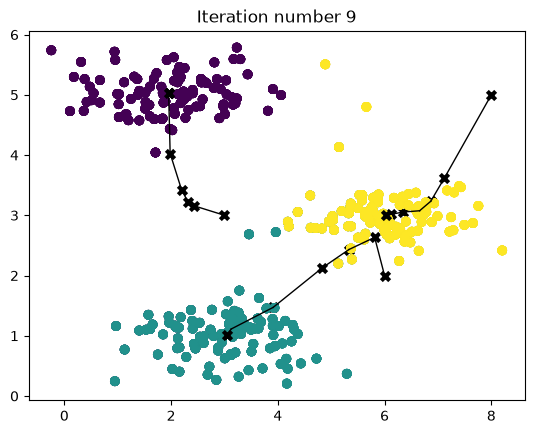

In [9]:
# 加载示例数据集
X = load_data()

# 设置初始质心
initial_centroids = np.array([[3,3],[6,2],[8,5]])
K = 3

# 迭代次数
max_iters = 10

centroids, idx = run_kMeans(X, initial_centroids, max_iters, plot_progress=True)

<a name="3"></a>
## 3 - 随机初始化

示例数据集的质心初始分配是专门设计的，以便你看到的图与图 1 相同。在实践中，初始化质心的一个好策略是从训练集中随机选择样本。

在练习的这一部分，你应该理解函数 `kMeans_init_centroids` 是如何实现的。
* 代码首先随机打乱样本的索引（使用 `np.random.permutation()`）。 
* 然后，根据随机排列后的索引选出前 $K$ 个样本。 
    * 这样既能随机选取样本，又不会有重复选中同一样本的风险。

**注意**：练习的这一部分你不需要实现任何内容。

In [10]:
# 你不需要修改这一部分

def kMeans_init_centroids(X, K):
    """
    This function initializes K centroids that are to be 
    used in K-Means on the dataset X
    
    Args:
        X (ndarray): Data points 
        K (int):     number of centroids/clusters
    
    Returns:
        centroids (ndarray): Initialized centroids
    """
    
    # 随机重排样本的索引
    randidx = np.random.permutation(X.shape[0])
    
    # 取前 K 个样本作为质心
    centroids = X[randidx[:K]]
    
    return centroids

<a name="4"></a>
## 4 - 用 K-means 压缩图像

在本练习中，你将把 K-means 应用于图像压缩。 

* 在图像直观的 24 位颜色表示中$^{2}$，每个像素由三个 8 位无符号整数（范围 0 到 255）表示，分别指定红、绿、蓝的强度值。这种编码通常称为 RGB 编码。
* 我们的图像包含成千上万种颜色，在练习的这一部分，你将把颜色数量减少到 16 种。
* 通过这种缩减，可以高效地表示（压缩）这张照片。 
* 具体来说，你只需要存储所选 16 种颜色的 RGB 值；对图像中的每个像素，现在只需要存储该位置颜色的索引（只需 4 位即可表示 16 种可能）。

在这一部分，你将用 K-means 算法选出用于表示压缩图像的 16 种颜色。
* 具体来说，你将把原始图像中的每个像素视为一个数据样本，用 K-means 算法在三维 RGB 空间中找到能把像素最好地分组（聚类）的 16 种颜色。 
* 一旦算出了图像上的簇质心，你就可以用这 16 种颜色替换原始图像中的像素。

<img src="images/figure 2.png" width="500" height="500">

$^{2}$<sub>本练习中提供的照片属于 Frank Wouters，经其许可使用。</sub>

<a name="4.1"></a>
### 4.1 数据集

**加载图像**

首先，你将用 `matplotlib` 读入原始图像，如下所示。

In [11]:
# 加载一张鸟的图像
original_img = plt.imread('bird_small.png')

**可视化图像**

你可以用下面的代码可视化刚加载的图像。

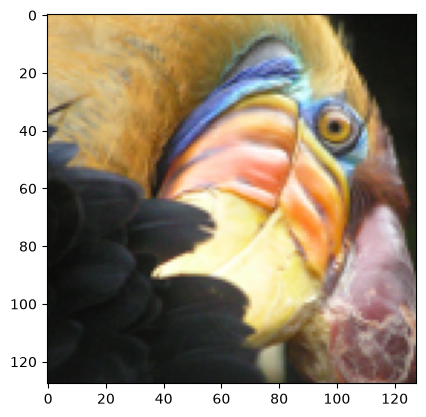

In [12]:
# 可视化图像
plt.imshow(original_img)

**检查变量的维度**

和往常一样，你将打印变量的形状来进一步熟悉数据。

In [13]:
print("Shape of original_img is:", original_img.shape)

Shape of original_img is: (128, 128, 3)


如你所见，这创建了一个三维矩阵 `original_img`，其中 
* 前两个索引标识像素位置，
* 第三个索引表示红、绿或蓝。 

例如，`original_img[50, 33, 2]` 给出第 50 行、第 33 列像素的蓝色强度。

#### 处理数据

要调用 `run_kMeans`，需要先把矩阵 `original_img` 转换成二维矩阵。

* 下面的代码把矩阵 `original_img` 重塑为一个 $m \times 3$ 的像素颜色矩阵（其中
$m=16384 = 128\times128$）

In [14]:
# 除以 255，使所有值落在 0 - 1 范围内
original_img = original_img / 255

# 把图像重塑为 m x 3 矩阵，其中 m = 像素数量
# （本例中 m = 128 x 128 = 16384）
# 每行包含红、绿、蓝像素值
# 这就得到了我们将用 K-Means 处理的数据集矩阵 X_img。

X_img = np.reshape(original_img, (original_img.shape[0] * original_img.shape[1], 3))

<a name="4.2"></a>
### 4.2 在图像像素上运行 K-Means

现在，运行下面的单元格，在预处理后的图像上运行 K-Means。

In [15]:
# 在这个数据上运行你的 K-Means 算法
# 你应该在这里尝试不同的 K 和 max_iters 取值
K = 16                       
max_iters = 10               

# 使用你在上面实现的函数。 
initial_centroids = kMeans_init_centroids(X_img, K) 

# 运行 K-Means——这需要几分钟
centroids, idx = run_kMeans(X_img, initial_centroids, max_iters) 

K-Means iteration 0/9


K-Means iteration 1/9


K-Means iteration 2/9


K-Means iteration 3/9


K-Means iteration 4/9


K-Means iteration 5/9


K-Means iteration 6/9


K-Means iteration 7/9


K-Means iteration 8/9


K-Means iteration 9/9


In [16]:
print("Shape of idx:", idx.shape)
print("Closest centroid for the first five elements:", idx[:5])

Shape of idx: (16384,)
Closest centroid for the first five elements: [7 7 7 7 7]


<a name="4.3"></a>
### 4.3 压缩图像


找到用于表示图像的前 $K=16$ 种颜色后，你就可以用 `find_closest_centroids` 函数把每个像素位置分配给离它最近的质心。 
* 这样你就可以用每个像素的质心分配结果来表示原始图像。 
* 注意，你已经大幅减少了描述图像所需的比特数。 
    * 原始图像的 $128\times128$ 个像素位置每个需要 24 位，总大小为 $128 \times 128 \times 24 = 393,216$ 位。 
    * 新表示需要一些额外开销：一个 16 种颜色的字典，每种颜色需要 24 位；但图像本身随后每个像素位置只需要 4 位。 
    * 因此最终使用的比特数为 $16 \times 24 + 128 \times 128 \times 4 = 65,920$ 位，相当于把原始图像压缩了约 6 倍。

In [17]:
# 用索引表示图像
X_recovered = centroids[idx, :] 

# 把还原的图像重塑为正确的维度
X_recovered = np.reshape(X_recovered, original_img.shape) 

最后，你可以仅根据质心分配结果重建图像，查看压缩的效果。 
* 具体来说，可以把每个像素位置替换为分配给它的质心均值。 
* 图 3 展示了我们得到的重建结果。尽管生成的图像保留了原始图像的大部分特征，但也能看到一些压缩伪影。

<img src="images/figure 3.png" width="700" height="700">


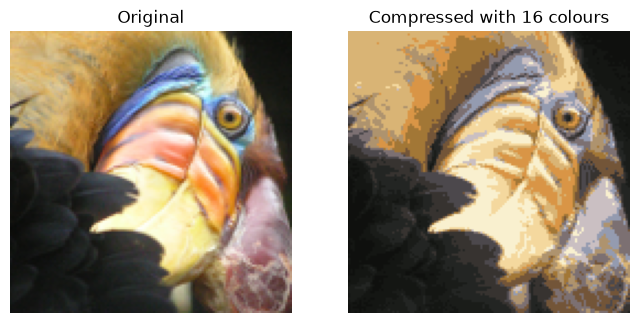

In [18]:
# 显示原始图像
fig, ax = plt.subplots(1,2, figsize=(8,8))
plt.axis('off')

ax[0].imshow(original_img*255)
ax[0].set_title('Original')
ax[0].set_axis_off()


# 显示压缩后的图像
ax[1].imshow(X_recovered*255)
ax[1].set_title('Compressed with %d colours'%K)
ax[1].set_axis_off()